# Our pipeline, told as a story

**For the three of us (Shamsul Hakimee, Amirul Iman, Syazani Akmal), and for anyone we have to explain our work to.**

This notebook walks through what we built, in the order we learned it. Every picture is made from our own data and
our own saved predictions. Nothing here is a mock-up.

- It runs on a laptop. No GPU and no training: it only reads files that are already in the repository.
- Running all cells takes about two minutes.
- Each chapter ends with a line called **"Say it like this"**: one or two sentences you can use when someone asks.
- The last chapter is a list of questions people are likely to ask us, with short answers.

| Chapter | Question it answers |
|---|---|
| 1 | What is the task? |
| 2 | Why is it hard, even for people? |
| 3 | How is our answer scored? |
| 4 | What is the model? |
| 5 | What does one model give us? |
| 6 | Lesson 1: why the full image size matters |
| 7 | Lesson 2: why we look at each image four times |
| 8 | Lesson 3: why we use two models |
| 9 | The clean-up rules |
| 10 | The final result, and how it is judged |
| 11 | The whole journey in one chart, and the ideas that failed |
| 12 | How we know which gains are real |
| 13 | Where we still lose points |
| 14 | Speed, and proof that it can be reproduced |
| 15 | The one-minute version, and questions people may ask |

## Setup
Run these three cells first. You do not need to read them to follow the story.

In [1]:
from pathlib import Path
import json, sys
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mp
from matplotlib.lines import Line2D
from matplotlib import colors as mcolors
from pycocotools import mask as cm

# find the repository folder (works when the notebook is opened from notebooks/ or from the top folder)
ROOT = Path.cwd()
while not (ROOT / "src" / "final_pipeline.py").exists():
    assert ROOT != ROOT.parent, "Open this notebook from inside the repository folder."
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from config import CFG
from annotations import load_gt_entries, entry_stem
from split import load_split
from utils.rle import load_predictions
from utils.flip import flip
from ensemble import fuse_image
from postprocess import close_all
from evaluate import evaluate_official
import final_pipeline as fp          # the final pipeline: we use its real settings and functions

R = ROOT / "results"
M = R / "phase6" / "Mirul"
pd.set_option("display.max_colwidth", None)
plt.rcParams.update({"figure.dpi": 90, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#b9b8b2", "xtick.color": "#52514e", "ytick.color": "#52514e"})
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"   # chart colours
INK, MUTED = "#0b0b0b", "#52514e"
OVER = ["#ffd21f", "#39d5ff", "#ff7bd1", "#9dff5c"]                       # bright colours for drawing on the Sun
HIT, FALSE_ALARM, MISSED = "#4be37a", "#ff5a4d", "#ffffff"
print("Repository folder:", ROOT)

Repository folder: C:\Users\Victus\OneDrive\Desktop\Solar_Filament_Kaggle


In [2]:
# Small drawing tools
FULL = (0, 0, 2048, 2048)

def load_img(stem):
    return cv2.imread(str(CFG.paths.TRAIN_IMG_DIR / f"{stem}.jpeg"), cv2.IMREAD_GRAYSCALE)

def mask(r):
    """Stored mask -> picture of True/False pixels."""
    return cm.decode({"size": r["size"], "counts": r["counts"]}).astype(bool)

def iou(a, b):
    """Overlap score (0..1) of every mask in list a with every mask in list b."""
    if not a or not b:
        return np.zeros((len(a), len(b)))
    return np.asarray(cm.iou(a, b, [0] * len(b)), dtype=float)

def box_around(rles, pad=60):
    """A square crop (x0, y0, x1, y1) around some masks."""
    b = np.array([cm.toBbox(r) for r in rles])
    x0, y0 = b[:, 0].min() - pad, b[:, 1].min() - pad
    x1, y1 = (b[:, 0] + b[:, 2]).max() + pad, (b[:, 1] + b[:, 3]).max() + pad
    side = max(x1 - x0, y1 - y0)
    x0, y0 = int(max((x0 + x1 - side) / 2, 0)), int(max((y0 + y1 - side) / 2, 0))
    return x0, y0, int(min(x0 + side, 2048)), int(min(y0 + side, 2048))

def show(ax, picture, box=FULL, title=""):
    x0, y0, x1, y1 = box
    ax.imshow(picture[y0:y1, x0:x1], cmap="gray", vmin=0, vmax=255, extent=(x0, x1, y1, y0), interpolation="nearest")
    ax.set_title(title, fontsize=10, color=INK)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    ax._box = box

def _keep_frame(ax):
    x0, y0, x1, y1 = ax._box
    ax.set_xlim(x0, x1); ax.set_ylim(y1, y0)

def outline(ax, r, color, lw=1.8, ls="-"):
    contours, _ = cv2.findContours(mask(r).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    for c in contours:
        c = np.vstack([c[:, 0, :], c[:1, 0, :]]) + 0.5
        ax.plot(c[:, 0], c[:, 1], color=color, lw=lw, ls=ls)
    _keep_frame(ax)

def fill(ax, r, color, alpha=0.9):
    x0, y0, x1, y1 = ax._box
    m = mask(r)[y0:y1, x0:x1]
    rgba = np.zeros(m.shape + (4,))
    rgba[m] = (*mcolors.to_rgb(color), alpha)
    ax.imshow(rgba, extent=(x0, x1, y1, y0), interpolation="nearest")
    _keep_frame(ax)

def key(fig, items, y=0.02):
    """A small legend under a figure: items = [(colour, text, 'line' / 'dash' / 'patch')]."""
    handles = [mp.Patch(fc=c, ec="#55554f", label=t) if kind == "patch"
               else Line2D([], [], color=c, lw=2.2, ls="--" if kind == "dash" else "-", label=t) for c, t, kind in items]
    leg = fig.legend(handles=handles, loc="lower center", ncol=len(items), frameon=True, fontsize=9, bbox_to_anchor=(0.5, y))
    leg.get_frame().set_facecolor("#6e6e6a"); leg.get_frame().set_edgecolor("none")
    for t in leg.get_texts():
        t.set_color("white")

In [3]:
# The data we follow through the whole story
STEM = "20110803164914Mh"                 # one validation image; three people labelled it
_, val_ids = load_split()                 # the 141 validation images (never used for training)
gt_all = load_gt_entries(val_ids)         # every annotator's labels of every validation image
gt = {e: g for e, g in gt_all.items() if entry_stem(e) == STEM}
A, B, C = list(gt)
names = {A: "Annotator A", B: "Annotator B", C: "Annotator C"}
all_gt = [r for g in gt.values() for r in g]
img = load_img(STEM)
print(f"Validation images: {len(val_ids)}.  Our example image: {STEM}, labelled by {len(gt)} people.")

Validation images: 141.  Our example image: 20110803164914Mh, labelled by 3 people.


## 1. The task

A **solar filament** is a thin, dark thread on the Sun: a cloud of cooler gas held up by the Sun's magnetic field.
When a filament erupts, it can throw material towards Earth, so solar physicists want to track every one of them.

The images come from GONG, a network of six telescopes around the world. They photograph the Sun in **H-alpha**, a
red colour of light in which filaments show up dark. Each image is 2048 × 2048 pixels.

Our job is **instance segmentation**: for each image, give **one mask per filament**. A mask is the exact set of
pixels that belong to that filament. It is not enough to mark "filament pixels" in general. We must say which pixels
belong to filament 1, which to filament 2, and so on.

We had 707 labelled images to learn from, and 180 test images with no labels to predict.

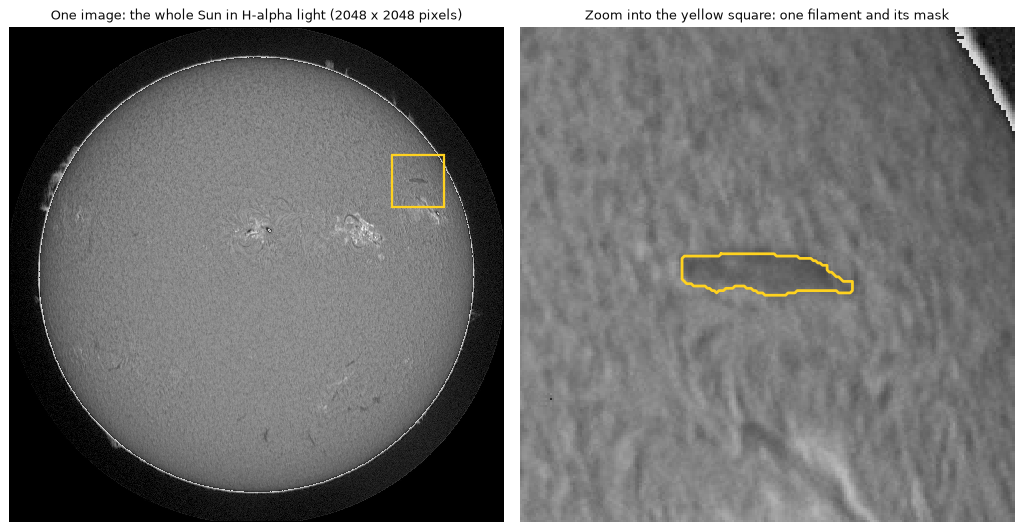

The zoom is 215 pixels wide. This filament covers 1075 pixels: 0.026% of the image.


In [4]:
hero = gt[A][6]                           # one filament, as Annotator A drew it
zoom = box_around([hero], pad=70)

fig, ax = plt.subplots(1, 2, figsize=(11.5, 5.8))
show(ax[0], img, title="One image: the whole Sun in H-alpha light (2048 x 2048 pixels)")
x0, y0, x1, y1 = zoom
ax[0].add_patch(mp.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=OVER[0], lw=1.8))
show(ax[1], img, zoom, "Zoom into the yellow square: one filament and its mask")
outline(ax[1], hero, OVER[0], lw=2.2)
plt.tight_layout(); plt.show()
print(f"The zoom is {x1 - x0} pixels wide. This filament covers {int(cm.area(hero))} pixels:",
      f"{100 * cm.area(hero) / 2048**2:.3f}% of the image.")

Look at the size. A filament is a few hundred to a few thousand pixels in an image of four million. The dark thread
has fuzzy edges, and thin side branches called *barbs*. This is the first reason the task is hard: the things we
look for are **small, thin and faint**.

> **Say it like this:** "For every image of the Sun we output one mask per filament. Filaments are tiny dark threads,
> often less than a thousandth of the image."

## 2. The first surprise: people do not agree

296 of the 707 training images were labelled by two or three people, each working alone. Our example image is one
of them. Here is what each person drew on the **same** image.

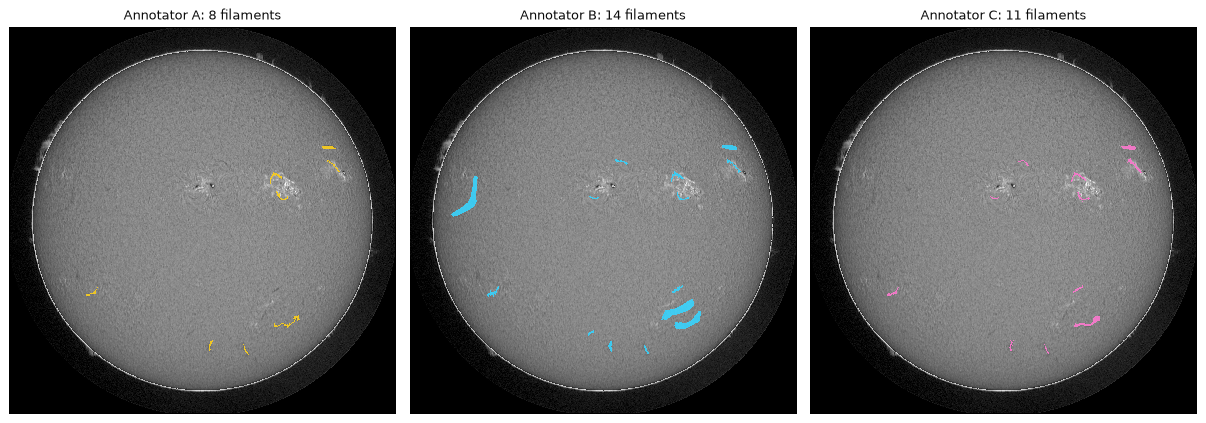

Annotator A drew 8 filaments. 6 of them match one of Annotator B's 14.
Annotator A drew 8 filaments. 7 of them match one of Annotator C's 11.
Annotator B drew 14 filaments. 9 of them match one of Annotator C's 11.


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(13.5, 4.9))
for a, e, colour in zip(ax, gt, OVER):
    show(a, img, title=f"{names[e]}: {len(gt[e])} filaments")
    for r in gt[e]:
        fill(a, r, colour)
plt.tight_layout(); plt.show()

for i, j in [(A, B), (A, C), (B, C)]:
    same = int((iou(gt[i], gt[j]) > 0.5).any(axis=1).sum())
    print(f"{names[i]} drew {len(gt[i])} filaments. {same} of them match one of {names[j]}'s {len(gt[j])}.")

Three people, three different counts. Let us zoom into one region where they clearly differ.

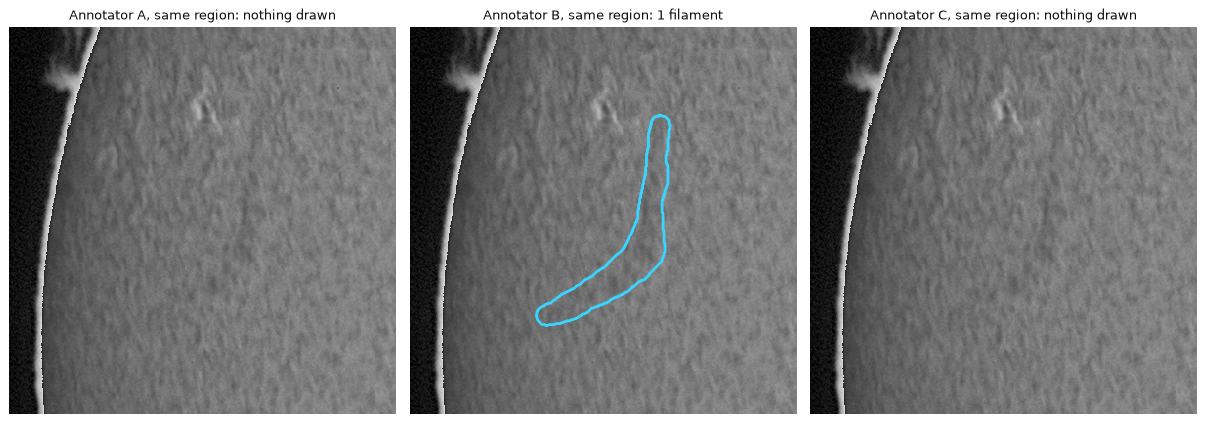

In [6]:
big = max(gt[B], key=lambda r: cm.area(r))            # the largest region Annotator B outlined
region_b = box_around([big], pad=90)
fig, ax = plt.subplots(1, 3, figsize=(13.5, 4.9))
x0, y0, x1, y1 = region_b
for a, e, colour in zip(ax, gt, OVER):
    inside = [r for r in gt[e] if mask(r)[y0:y1, x0:x1].any()]
    show(a, img, region_b, f"{names[e]}, same region: " + (f"{len(inside)} filament" + ("s" if len(inside) > 1 else "")
                                                         if inside else "nothing drawn"))
    for r in inside:
        outline(a, r, colour, lw=2.2)
plt.tight_layout(); plt.show()

One person outlined a long faint structure. The other two left the region empty.

Nobody here is wrong. Where does a faint filament end? Is this one long filament or two short ones? Is that dark
patch a filament at all? Honest experts answer differently.

We measured this over the whole dataset. If you treat one person's labels as the answer and score another person
against them, the second person gets **PQ 0.336** (the score is explained in the next chapter; 1.0 would be perfect).
So a perfect score is not possible, because there is no single correct answer.

This changed three things for us:

1. **Training:** we train on every person's labels, each as its own example. The model learns the "average" way of
   drawing a filament.
2. **Scoring:** the official score compares our prediction with each person's labels in turn and pools the results.
   We built our own copy of that score and checked that it gives exactly the organisers' number.
3. **Expectations:** part of what counts as our "errors" is really disagreement between people.

> **Say it like this:** "Even experts disagree on these images. Two annotators only score 0.34 against each other, so
> the labels are noisy and no model can reach a perfect score."

## 3. How we are scored: Panoptic Quality (PQ)

The score answers two questions about our masks.

**First: did we find the filament?** A predicted mask and a labelled mask are compared by **IoU**
(intersection over union): the area they share, divided by the area they cover together. IoU is 1 for identical
masks and 0 for masks that do not touch. A filament counts as **found** only if the IoU is **above 0.5**.

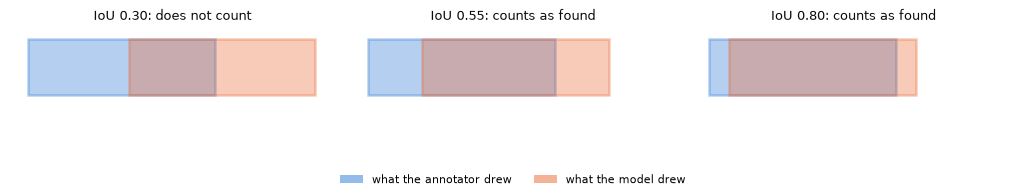

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(11.5, 2.5))
for a, shift in zip(ax, (5.4, 2.9, 1.1)):
    value = (10 - shift) / (10 + shift)               # shared area / total covered area
    a.add_patch(mp.Rectangle((0, 0), 10, 3, fc=BLUE, alpha=0.35, ec=BLUE, lw=2))
    a.add_patch(mp.Rectangle((shift, 0), 10, 3, fc=ORANGE, alpha=0.35, ec=ORANGE, lw=2))
    a.set_xlim(-1, 16.5); a.set_ylim(-0.6, 3.6); a.set_aspect("equal"); a.axis("off")
    a.set_title(f"IoU {value:.2f}: " + ("counts as found" if value > 0.5 else "does not count"), fontsize=10.5, color=INK)
fig.legend(handles=[mp.Patch(fc=BLUE, alpha=0.5, label="what the annotator drew"),
                    mp.Patch(fc=ORANGE, alpha=0.5, label="what the model drew")],
           loc="lower center", ncol=2, frameon=False, fontsize=9)
plt.tight_layout(rect=(0, 0.12, 1, 1)); plt.show()

That gives three kinds of outcome:

- **Hit** (true positive, TP): a predicted mask that matches a labelled filament.
- **False alarm** (false positive, FP): a predicted mask that matches nothing.
- **Miss** (false negative, FN): a labelled filament that no prediction matches.

**Second: how good are the outlines?** For the hits only, take the average IoU.

The score multiplies the two answers:

- **SQ** (segmentation quality) = average IoU of the hits. *How well did we draw the ones we found?*
- **RQ** (recognition quality) = hits ÷ (hits + half the false alarms + half the misses). *Did we find the right ones?*
- **PQ = SQ × RQ**

Try it. The next cell computes PQ for a few made-up situations with 10 filaments.

In [8]:
def pq(hit_ious, false_alarms, misses):
    hits = len(hit_ious)
    sq = sum(hit_ious) / hits if hits else 0.0
    rq = hits / (hits + 0.5 * false_alarms + 0.5 * misses) if hits + false_alarms + misses else 0.0
    return sq * rq, sq, rq

situations = [
    ("Every filament found, outlines perfect",                  [1.00] * 10, 0, 0),
    ("Every filament found, outlines typical (IoU 0.67)",       [0.67] * 10, 0, 0),
    ("Typical outlines, 3 missed",                              [0.67] * 7,  0, 3),
    ("Typical outlines, 3 missed and 3 false alarms",           [0.67] * 7,  3, 3),
    ("One filament cut into two pieces (1 extra false alarm)",  [0.67] * 9 + [0.55], 1, 0),
    ("Two filaments drawn as one (1 false alarm, 2 missed)",    [0.67] * 8,  1, 2),
]
pd.DataFrame([{"situation": s, "SQ": round(pq(i, f, m)[1], 2), "RQ": round(pq(i, f, m)[2], 2),
               "PQ": round(pq(i, f, m)[0], 2)} for s, i, f, m in situations]).set_index("situation")

,SQ,RQ,PQ
situation,,,
"Every filament found, outlines perfect",1.00,1.00,1.00
"Every filament found, outlines typical (IoU 0.67)",0.67,1.00,0.67
"Typical outlines, 3 missed",0.67,0.82,0.55
"Typical outlines, 3 missed and 3 false alarms",0.67,0.70,0.47
One filament cut into two pieces (1 extra false alarm),0.66,0.95,0.63
"Two filaments drawn as one (1 false alarm, 2 missed)",0.67,0.84,0.56


Three things to notice:

- With typical outlines (IoU 0.67) the best possible PQ is already only 0.67. Two human annotators reach SQ 0.63
  against each other, so nobody draws much better than that. **The outlines are limited by the labels.**
- So the part we can really move is **RQ**: find more real filaments and raise fewer false alarms.
- Cutting one filament in two, or joining two into one, is punished twice. That is why the pipeline has rules
  against overlapping and fragmented masks.

> **Say it like this:** "PQ is outline quality times detection quality. A filament counts as found only if our mask
> overlaps the label by more than half. Outline quality is capped by label noise, so we worked on finding the right
> filaments and avoiding false alarms."

## 4. The model: Mask R-CNN

We use **Mask R-CNN**, a well-known model for instance segmentation. It works in stages, like a person who first
scans a picture, then points at candidates, then traces each one.

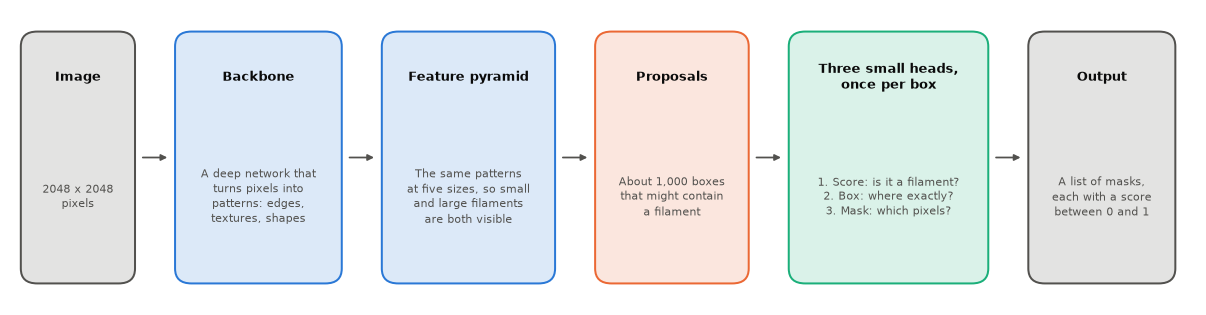

In [9]:
def block(ax, x, w, title, text, colour, y=3.0, h=4.2):
    ax.add_patch(mp.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.25", fc=colour, ec="none", alpha=0.16))
    ax.add_patch(mp.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.25", fc="none", ec=colour, lw=1.6))
    ax.text(x + w / 2, y + h - 0.75, title, ha="center", va="center", fontsize=10.5, color=INK, weight="bold")
    ax.text(x + w / 2, y + (h - 1.3) / 2, text, ha="center", va="center", fontsize=8.8, color=MUTED, linespacing=1.35)

fig, ax = plt.subplots(figsize=(13.5, 3.6))
steps = [
    ("Image", "2048 x 2048\npixels", MUTED),
    ("Backbone", "A deep network that\nturns pixels into\npatterns: edges,\ntextures, shapes", BLUE),
    ("Feature pyramid", "The same patterns\nat five sizes, so small\nand large filaments\nare both visible", BLUE),
    ("Proposals", "About 1,000 boxes\nthat might contain\na filament", ORANGE),
    ("Three small heads,\nonce per box", "1. Score: is it a filament?\n2. Box: where exactly?\n3. Mask: which pixels?", AQUA),
    ("Output", "A list of masks,\neach with a score\nbetween 0 and 1", MUTED),
]
widths = [1.7, 2.5, 2.6, 2.3, 3.0, 2.2]
x = 0.2
for (title, text, colour), w in zip(steps, widths):
    block(ax, x, w, title, text, colour)
    if title != "Output":
        ax.annotate("", xy=(x + w + 0.55, 5.1), xytext=(x + w + 0.1, 5.1), arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.4))
    x += w + 0.65
ax.set_xlim(0, x - 0.3); ax.set_ylim(2.6, 7.6); ax.axis("off")
plt.tight_layout(); plt.show()

A few facts worth knowing:

- **The mask head draws on a small grid.** Inside each box, the mask is drawn on a 28 × 28 grid and then stretched
  to the size of the box. For a long thin filament that is coarse. One of our two models uses a finer 56 × 56 grid.
- **We did not start from zero.** Both models start from weights already trained on COCO, a large set of everyday
  photos. They already know edges and shapes. We then trained them on the filament images for 6,000 steps
  (two images per step). This is called *fine-tuning*.
- **We told the model what shapes to expect.** Filaments are long and thin, so the candidate boxes include very
  wide and very tall shapes (up to 5 times longer than wide), and small sizes (from 8 pixels).
- **We use two versions:** a larger one (backbone "X101", 107 million numbers to learn, finer mask grid) and a smaller
  one (backbone "R50", 44 million). Chapter 8 explains why two.

> **Say it like this:** "Mask R-CNN first proposes boxes that may contain a filament, then for each box gives a
> confidence score and draws a mask inside it. We fine-tuned two versions that were pre-trained on COCO."

## 5. What one model gives us

Here is the raw output of the larger model on our example image: every mask it proposes with a score of at least 0.2.

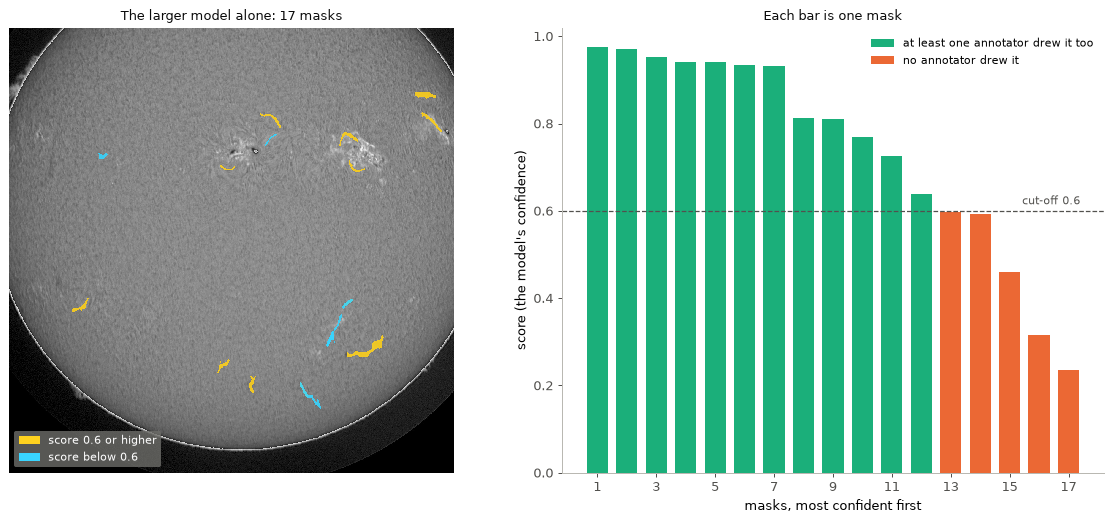

With score 0.6 or higher: 12 masks.  Below: 5.


In [10]:
raw_m28 = load_predictions(R / "phase5" / "step2" / "raw_preds_x101_2048_m28_val.json.gz")[STEM]
drawn_by_someone = (iou(raw_m28, all_gt) > 0.5).any(axis=1)      # did at least one annotator draw this filament?
region = box_around(all_gt + raw_m28, pad=40)

fig, ax = plt.subplots(1, 2, figsize=(13, 5.9))
show(ax[0], img, region, f"The larger model alone: {len(raw_m28)} masks")
for r in raw_m28:
    fill(ax[0], r, OVER[0] if r["score"] >= 0.6 else OVER[1])
ax[0].legend(handles=[mp.Patch(fc=OVER[0], label="score 0.6 or higher"), mp.Patch(fc=OVER[1], label="score below 0.6")],
             loc="lower left", fontsize=8.5, facecolor="#6e6e6a", edgecolor="none", labelcolor="white")

scores = [r["score"] for r in raw_m28]
ax[1].bar(range(1, len(scores) + 1), scores, width=0.72,
          color=[AQUA if d else ORANGE for d in drawn_by_someone])
ax[1].axhline(0.6, color=MUTED, lw=1, ls="--")
ax[1].text(len(scores) + 0.4, 0.615, "cut-off 0.6", ha="right", fontsize=9, color=MUTED)
ax[1].set_xlabel("masks, most confident first"); ax[1].set_ylabel("score (the model's confidence)")
ax[1].set_xticks(range(1, len(scores) + 1, 2))
ax[1].set_ylim(0, 1.02); ax[1].set_title("Each bar is one mask", fontsize=10, color=INK)
ax[1].legend(handles=[mp.Patch(fc=AQUA, label="at least one annotator drew it too"),
                      mp.Patch(fc=ORANGE, label="no annotator drew it")], frameon=False, fontsize=9, loc="upper right")
plt.tight_layout(); plt.show()
print(f"With score 0.6 or higher: {sum(s >= 0.6 for s in scores)} masks.  Below: {sum(s < 0.6 for s in scores)}.")

The model is not simply right or wrong. It gives a **list with confidence scores**, and we must choose a cut-off.

- Cut high, and we keep only sure masks: few false alarms, but more misses.
- Cut low, and we find more filaments, but also keep more false alarms.

In this one image the scores sort the masks neatly: everything above the cut-off was also drawn by a person. Over
all 141 validation images it is less tidy. The next chart counts every mask of the larger model by its score.

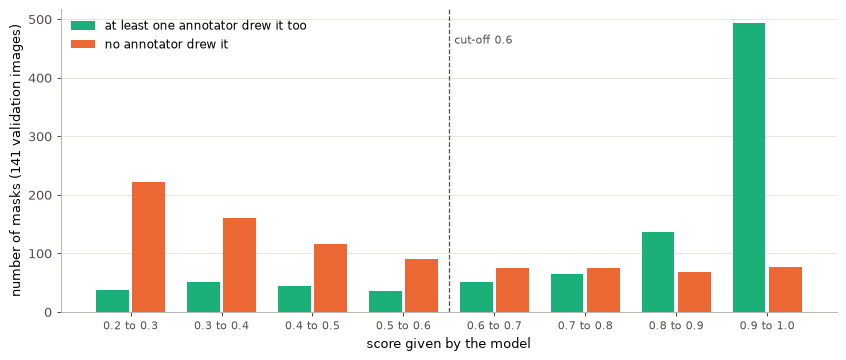

Masks with a score between 0.4 and 0.7: 133 were drawn by a person, 282 were not.


In [11]:
gt_by_image = {}
for e, g in gt_all.items():
    gt_by_image.setdefault(entry_stem(e), []).extend(g)

all_scores, all_drawn = [], []
for stem, masks in load_predictions(R / "phase5" / "step2" / "raw_preds_x101_2048_m28_val.json.gz").items():
    if masks:
        all_scores += [r["score"] for r in masks]
        all_drawn += (iou(masks, gt_by_image[stem]) > 0.5).any(axis=1).tolist()
all_scores, all_drawn = np.array(all_scores), np.array(all_drawn)

edges = np.arange(0.2, 1.01, 0.1)
real = np.histogram(all_scores[all_drawn], edges)[0]
false = np.histogram(all_scores[~all_drawn], edges)[0]
x = np.arange(len(real))
fig, ax = plt.subplots(figsize=(9.5, 4.1))
ax.bar(x - 0.2, real, width=0.36, color=AQUA, label="at least one annotator drew it too")
ax.bar(x + 0.2, false, width=0.36, color=ORANGE, label="no annotator drew it")
ax.axvline(3.5, color=MUTED, lw=1, ls="--")
ax.text(3.56, max(real) * 0.93, "cut-off 0.6", fontsize=9, color=MUTED)
ax.set_xticks(x); ax.set_xticklabels([f"{a:.1f} to {a + 0.1:.1f}" for a in edges[:-1]], fontsize=9)
ax.set_xlabel("score given by the model"); ax.set_ylabel("number of masks (141 validation images)")
ax.grid(axis="y", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=9.5, loc="upper left")
plt.tight_layout(); plt.show()
k = (all_scores >= 0.4) & (all_scores < 0.7)
print(f"Masks with a score between 0.4 and 0.7: {int(all_drawn[k].sum())} were drawn by a person, {int((~all_drawn[k]).sum())} were not.")

At the top (0.9 and above) almost every mask is a real filament. At the bottom most are false alarms. But in the
middle, around the cut-off, real filaments and false alarms are **mixed**, and false alarms even outnumber real
filaments. Wherever we put the cut-off, we lose real filaments on one side or keep false alarms on the other.

**The model's confidence is the weak point.** Chapter 13 shows this is where we lose the most. The next three chapters
are, in the end, all ways to get better masks and more trustworthy scores.

> **Say it like this:** "A single model gives masks with confidence scores. The scores are reliable at the top but
> mixed in the middle, so most of our work went into making the scores more trustworthy."

## 6. Lesson 1: do not shrink the image

Our first model shrank each image to 1024 × 1024 before looking at it. That is the usual habit: it saves memory and
time. But a filament that is 12 pixels wide becomes 6 pixels wide, and its thin side branches almost vanish.

Below is one filament as the two models saw it. Same recipe, same data. Only the image size differs.

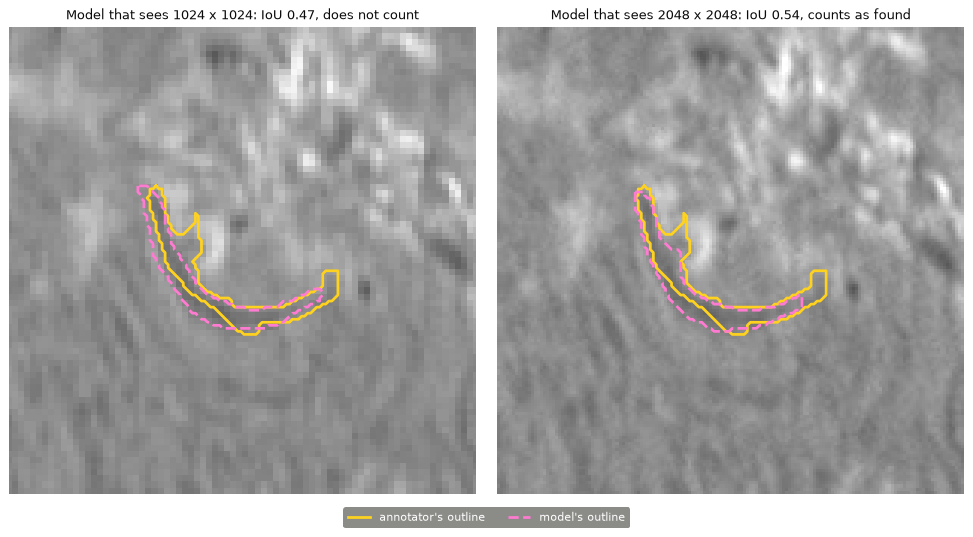

All 141 validation images, model that sees 1024 x 1024: PQ 0.3979  (hits 1003, false alarms 617, misses 675)
All 141 validation images, model that sees 2048 x 2048: PQ 0.4231  (hits 1049, false alarms 578, misses 629)


In [12]:
at_1024 = [r for r in load_predictions(R / "phase3" / "step3" / "raw_preds_r50_allann_val.json.gz")[STEM] if r["score"] >= 0.6]
at_2048 = [r for r in load_predictions(R / "phase4" / "raw_preds_r50_2048_val.json.gz")[STEM] if r["score"] >= 0.6]
target = gt[A][1]
crop = box_around([target], pad=45)
shrunk = cv2.resize(cv2.resize(img, (1024, 1024), interpolation=cv2.INTER_AREA), (2048, 2048), interpolation=cv2.INTER_NEAREST)

fig, ax = plt.subplots(1, 2, figsize=(11, 5.9))
for a, picture, preds, size in ((ax[0], shrunk, at_1024, "1024"), (ax[1], img, at_2048, "2048")):
    overlap = iou([target], preds)[0]
    best = int(overlap.argmax())
    verdict = "counts as found" if overlap[best] > 0.5 else "does not count"
    show(a, picture, crop, f"Model that sees {size} x {size}: IoU {overlap[best]:.2f}, {verdict}")
    outline(a, target, OVER[0], lw=2.2)
    outline(a, preds[best], OVER[2], lw=2.2, ls="--")
key(fig, [(OVER[0], "annotator's outline", "line"), (OVER[2], "model's outline", "dash")])
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

table = json.loads((R / "phase4" / "eval_phase4.json").read_text())
for run, label in (("r50_allann", "sees 1024 x 1024"), ("r50_2048", "sees 2048 x 2048")):
    r = next(x for x in table if x["run"] == run and x["thr"] == 0.6)
    print(f"All 141 validation images, model that {label}: PQ {r['PQ']:.4f}  (hits {r['TP']}, false alarms {r['FP']}, misses {r['FN']})")

This was our biggest single gain: **+0.027 PQ**, and the leaderboard moved from 0.35 to 0.36, then 0.37 with the
larger backbone. Working at full size needs a large graphics card (the bigger model used 20 GB while training), so
this part ran on a rented A100.

We had first planned to cut each image into overlapping tiles and stitch the results. Feeding the whole image at
once turned out to fit in memory, and it avoids filaments being cut at tile borders. So we dropped tiling.

> **Say it like this:** "Filaments are only a few pixels wide. Shrinking the image to 1024 destroys that detail, so we
> train and predict at the full 2048 resolution. That was our largest improvement."

## 7. Lesson 2: look at every image four times

The Sun has no "up". A filament is still a filament if the image is mirrored or turned upside down. But the model
gives slightly different answers on a mirrored image, because it is not perfect.

We use that. At prediction time each model looks at **four versions** of the image, and the masks are flipped back
to the normal orientation. This is called **test-time augmentation** (TTA). It costs no training, only time.

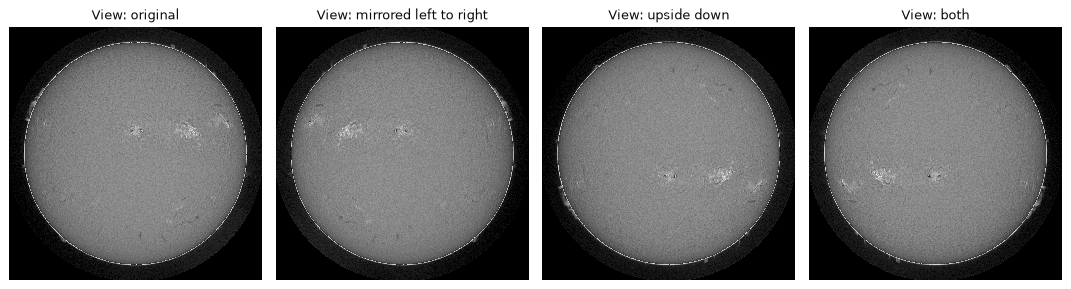

In [13]:
fig, ax = plt.subplots(1, 4, figsize=(12, 3.25))
for a, mode, text in zip(ax, ("none", "h", "v", "hv"), ("original", "mirrored left to right", "upside down", "both")):
    show(a, flip(img, mode), title=f"View: {text}")
plt.tight_layout(); plt.show()

Now we have four lists of masks for the same image. We merge them like this (`src/ensemble.py`):

- Masks from different views that overlap by IoU 0.5 or more are **the same filament**.
- Its mask becomes the **union** of the views (every pixel that any view marked).
- Its score becomes the **average over all four views**. A view that did not see it counts as **zero**.

The last rule is the important one. Two real cases from our example image:

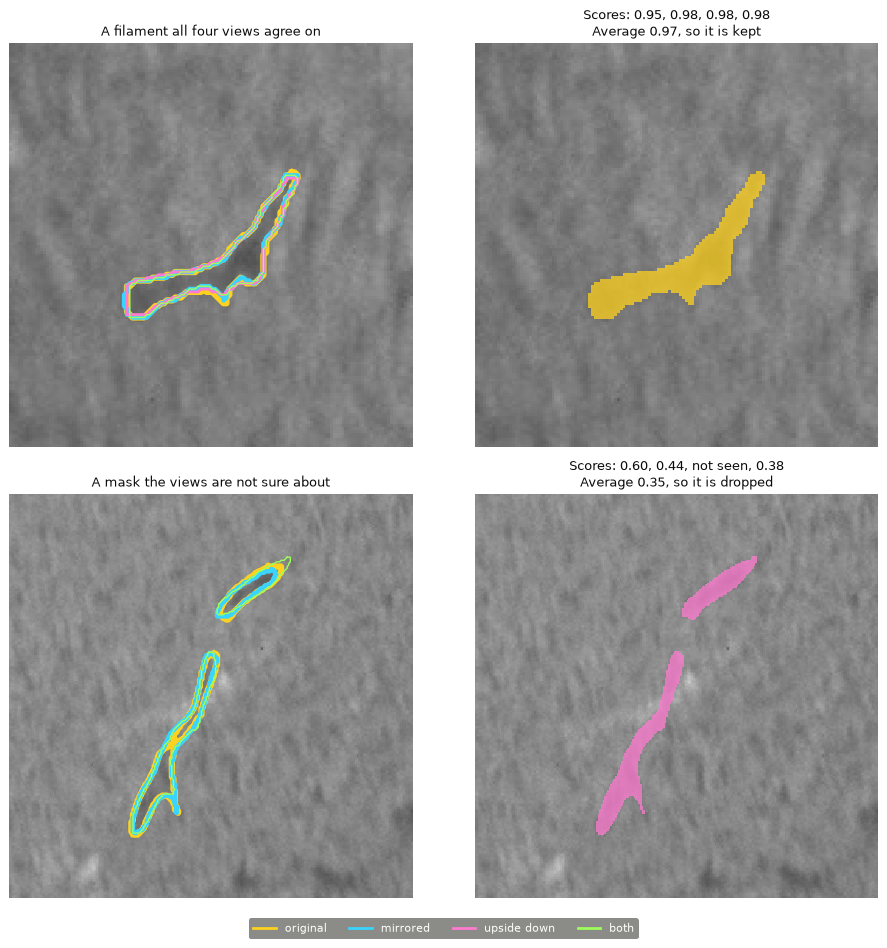

In [14]:
def views_of(first_file, model_name):
    """The four lists of masks of one model for our image: original, h, v, hv."""
    return [load_predictions(first_file)[STEM]] + \
           [load_predictions(M / f"raw_preds_{model_name}_flip{f}_val.json.gz")[STEM] for f in ("h", "v", "hv")]

views_1 = views_of(R / "phase5" / "step2" / "raw_preds_x101_2048_m28_val.json.gz", "x101_2048_m28")   # larger model
views_2 = views_of(R / "phase4" / "raw_preds_r50_2048_val.json.gz", "r50_2048")                          # smaller model
model_1 = fuse_image(views_1, fp.VIEW_IOU, fp.VIEW_MODE)       # the real fusion code, with the real settings
model_2 = fuse_image(views_2, fp.VIEW_IOU, fp.VIEW_MODE)

def seen_by(fused, views):
    """For one fused mask: the mask each view contributed (None if that view did not see it)."""
    out = []
    for v in views:
        overlap = iou([fused], v)[0]
        k = int(overlap.argmax()) if len(overlap) else -1
        out.append(v[k] if k >= 0 and overlap[k] >= 0.4 else None)
    return out

sure = model_1[0]
doubtful = next(f for f in model_1 if f["score"] < 0.5 and None in seen_by(f, views_1)
                and max(m["score"] for m in seen_by(f, views_1) if m) >= 0.55)

fig, ax = plt.subplots(2, 2, figsize=(10.5, 10.6))
for row, (fused, label) in enumerate(((sure, "A filament all four views agree on"), (doubtful, "A mask the views are not sure about"))):
    parts = seen_by(fused, views_1)
    crop = box_around([fused] + [p for p in parts if p], pad=40)
    show(ax[row, 0], img, crop, label)
    for p, colour, width in zip(parts, OVER, (5.0, 3.6, 2.3, 1.1)):     # thick to thin, so every view stays visible
        if p:
            outline(ax[row, 0], p, colour, lw=width)
    text = ", ".join(f"{p['score']:.2f}" if p else "not seen" for p in parts)
    kept = "kept" if fused["score"] >= fp.SCORE_THR else "dropped"
    show(ax[row, 1], img, crop, f"Scores: {text}\nAverage {fused['score']:.2f}, so it is {kept}")
    fill(ax[row, 1], fused, OVER[0] if kept == "kept" else OVER[2], alpha=0.75)
key(fig, [(c, t, "line") for c, t in zip(OVER, ("original", "mirrored", "upside down", "both"))], y=0.005)
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()

The top filament is seen by all four views with high scores, so it stays. The bottom mask got a borderline score in
one view, low scores in two others, and one view did not see it at all. Averaged, it falls far below the cut-off.

So looking four times does two things: the outline becomes more complete (the union), and the score becomes more
honest (a mask must be found again and again to keep a high score).

> **Say it like this:** "At test time each model sees the image four ways: normal, mirrored, upside down and both. A
> mask keeps a high score only if the model finds it in most of the views. One-off detections are averaged away."

## 8. Lesson 3: two different models must agree

Two models that were built differently make different mistakes. Where both see the same filament, we can trust it
more. So we merge the two models' lists (each already merged over its four views) with almost the same rule:

- Masks that overlap by IoU 0.3 or more are the same filament.
- Its mask becomes the **intersection** (only pixels that **both** models marked).
- Its score becomes the **average of the two models**. A model that did not see it counts as zero.

Why union for the views but intersection for the models? We tested the combinations on the validation images. The
four views of one model differ by small shifts, and adding them up completes the outline. The two models differ more,
and the area they share is the part that best matches what annotators draw.

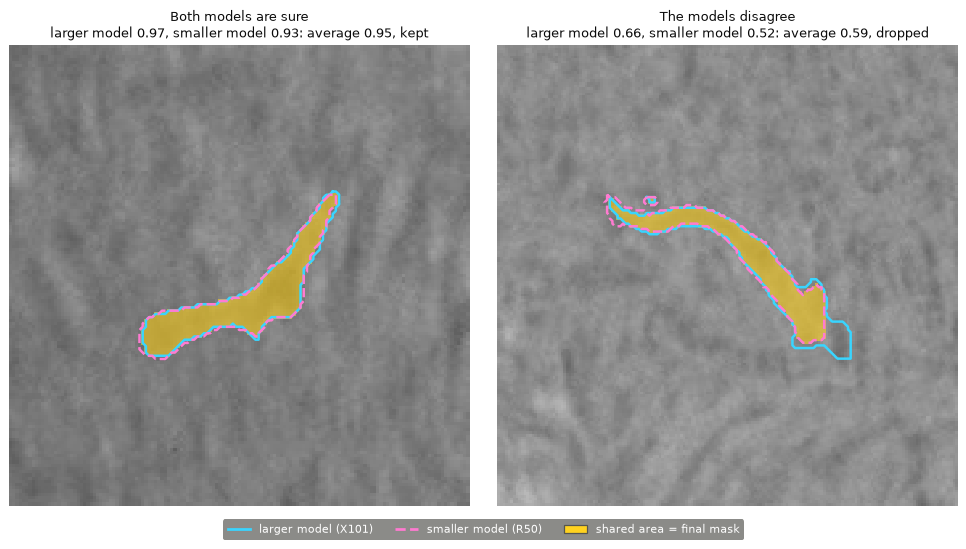

The dropped mask on the right: no annotator drew a filament there, so dropping it removed a false alarm.
Check: the masks computed in this notebook are identical to the saved ones of our final submission.


In [15]:
both = fuse_image([model_1, model_2], fp.MODEL_IOU, fp.MODEL_MODE)       # the real second fusion step

def partner(f, others):
    overlap = iou([f], others)[0]
    k = int(overlap.argmax())
    return others[k] if overlap[k] >= fp.MODEL_IOU else None

agree = model_1[0]
clash = next(f for f in model_1 if f["score"] >= 0.6 and partner(f, model_2) is not None
             and (f["score"] + partner(f, model_2)["score"]) / 2 < 0.6)

fig, ax = plt.subplots(1, 2, figsize=(11, 5.9))
for a, f, label in ((ax[0], agree, "Both models are sure"), (ax[1], clash, "The models disagree")):
    p = partner(f, model_2)
    mean = (f["score"] + p["score"]) / 2
    crop = box_around([f, p], pad=40)
    show(a, img, crop, f"{label}\nlarger model {f['score']:.2f}, smaller model {p['score']:.2f}: average {mean:.2f}, "
                       + ("kept" if mean >= fp.SCORE_THR else "dropped"))
    fill(a, cm.merge([f, p], intersect=True), OVER[0], alpha=0.6)
    outline(a, f, OVER[1], lw=2)
    outline(a, p, OVER[2], lw=2, ls="--")
key(fig, [(OVER[1], "larger model (X101)", "line"), (OVER[2], "smaller model (R50)", "dash"), (OVER[0], "shared area = final mask", "patch")])
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

a_human_drew_it = bool((iou([clash], all_gt) > 0.5).any())
print("The dropped mask on the right:", "an annotator did draw a filament there, so this drop costs us a hit."
      if a_human_drew_it else "no annotator drew a filament there, so dropping it removed a false alarm.")

saved = load_predictions(M / "raw_preds_tta2_m28_r50_val.json.gz")[STEM]
assert [r["counts"] for r in both] == [r["counts"] for r in saved]
print("Check: the masks computed in this notebook are identical to the saved ones of our final submission.")

The rule is not magic. Sometimes it removes a real filament that only one model was sure about. Over all validation
images it removes far more false alarms than hits. Here is each step, measured on the 141 validation images with the
same cut-off of 0.6:

In [16]:
def saved_row(path, **wanted):
    data = json.loads(Path(path).read_text())
    rows = data["rows"] if isinstance(data, dict) else data
    return next(r for r in rows if all(r.get(k) == v for k, v in wanted.items()))

ladder = [
    ("Larger model alone",                saved_row(R / "phase5" / "step2" / "single_x101_2048_m28.json", score_threshold=0.6)),
    ("Smaller model alone",               saved_row(R / "phase4" / "eval_phase4.json", run="r50_2048", thr=0.6)),
    ("Larger model, four views merged",   saved_row(M / "tta_m28.json", match_iou=0.5, mask_mode="union", score_threshold=0.6)),
    ("Smaller model, four views merged",  saved_row(M / "tta_r50.json", match_iou=0.5, mask_mode="union", score_threshold=0.6)),
    ("Both models merged (final)",        saved_row(M / "tta2_m28_r50.json", match_iou=0.3, mask_mode="inter", score_threshold=0.6)),
]
pd.DataFrame([{"step": n, "PQ": round(r["PQ"], 4), "hits": r["TP"], "false alarms": r["FP"], "misses": r["FN"]}
              for n, r in ladder]).set_index("step")

,PQ,hits,false alarms,misses
step,,,,
Larger model alone,0.4355,1071,551,607
Smaller model alone,0.4231,1049,578,629
"Larger model, four views merged",0.4408,1070,513,608
"Smaller model, four views merged",0.4345,1070,527,608
Both models merged (final),0.4480,1083,495,595


Read the table from top to bottom. The final step has **more hits and fewer false alarms** than either model alone.

> **Say it like this:** "We combine a large and a small Mask R-CNN. A filament keeps a high score only when both
> models find it, and we keep the area both agree on. That gives more hits and fewer false alarms than either model."

## 9. The clean-up rules

After the two merging steps we have one list of masks with scores. Four simple rules turn it into the submission:

1. **Closing.** Fill gaps of up to a few pixels inside each mask, so a filament is not broken into pieces.
2. **Score cut-off 0.6.** Drop every mask with a lower score.
3. **Minimum size 50 pixels.** Drop tiny specks.
4. **No overlaps.** Kaggle rejects a file in which two masks share pixels. The higher-scoring mask keeps the shared
   pixels. If more than 20% of a mask is covered by better masks, that mask is dropped completely.

In [17]:
closed = close_all({STEM: both}, fp.CLOSE_KERNEL)[STEM]
above = [r for r in closed if r["score"] >= fp.SCORE_THR]
final = fp.postprocess({STEM: both})[STEM]                    # the real clean-up function of the final pipeline
print(f"Our example image: {len(both)} merged masks -> {len(above)} with score {fp.SCORE_THR} or higher "
      f"-> {len(final)} after the size and overlap rules.")

Our example image: 26 merged masks -> 11 with score 0.6 or higher -> 11 after the size and overlap rules.


Why 0.6? We tried a range of cut-offs on the validation images and took the best region. The chart shows the score
for each cut-off, for the larger model alone and for the final pipeline.

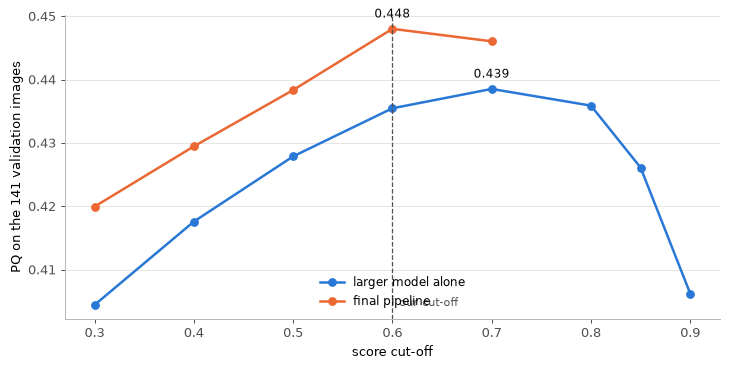

In [18]:
single = json.loads((R / "phase5" / "step2" / "single_x101_2048_m28.json").read_text())["rows"]
merged = [r for r in json.loads((M / "tta2_m28_r50.json").read_text())["rows"]
          if r["match_iou"] == 0.3 and r["mask_mode"] == "inter"]
single = [r for r in single if 0.3 <= r["score_threshold"] <= 0.9]

fig, ax = plt.subplots(figsize=(8.2, 4.2))
for rows, colour, label in ((single, BLUE, "larger model alone"), (merged, ORANGE, "final pipeline")):
    xs, ys = [r["score_threshold"] for r in rows], [r["PQ"] for r in rows]
    ax.plot(xs, ys, color=colour, lw=2, marker="o", ms=6, label=label)
    top = max(rows, key=lambda r: r["PQ"])
    ax.annotate(f"{top['PQ']:.3f}", (top["score_threshold"], top["PQ"]), textcoords="offset points", xytext=(0, 9),
                ha="center", fontsize=9.5, color=INK)
ax.axvline(0.6, color=MUTED, lw=1, ls="--")
ax.text(0.607, ax.get_ylim()[0] + 0.002, "our cut-off", fontsize=9, color=MUTED)
ax.set_xlabel("score cut-off"); ax.set_ylabel("PQ on the 141 validation images")
ax.grid(axis="y", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=9.5, loc="lower center")
plt.tight_layout(); plt.show()

Both curves are fairly flat near their top. That is good news: the result does not depend on a lucky setting. The
orange curve lies above the blue one almost everywhere, which is the gain from the four views and the two models.

> **Say it like this:** "After merging we fill small gaps, keep masks with a score of at least 0.6 and at least 50
> pixels, and remove overlaps. The cut-off was chosen on validation images, and the score is stable around it."

## 10. The result, and how it is judged

Here is our final answer for the example image, judged against each annotator in turn. The prediction is the same
in all three pictures. Only the judge changes.

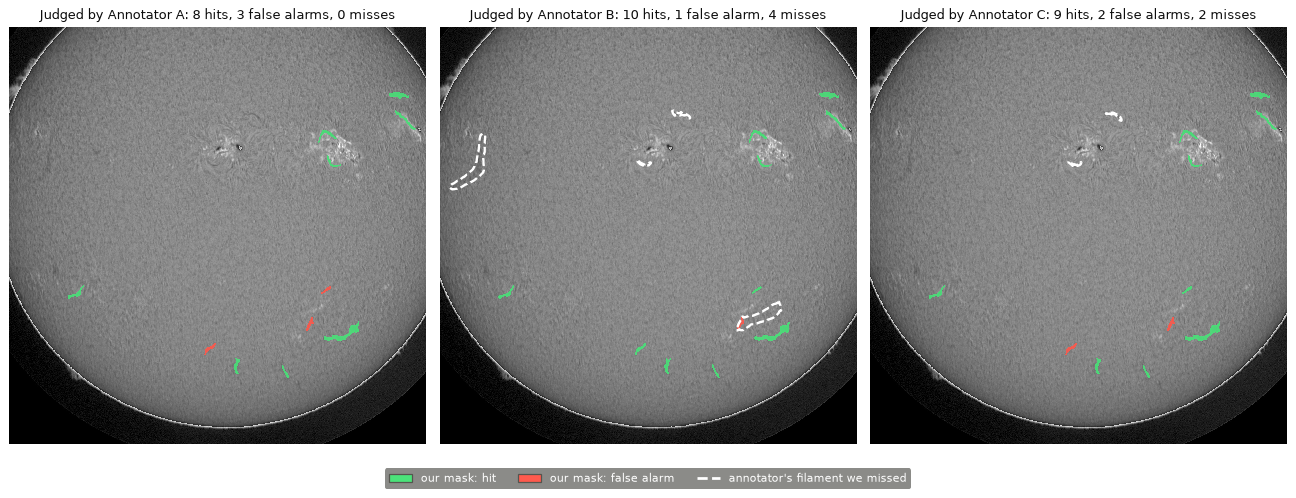

This image, all three judges pooled: PQ 0.549  (SQ 0.671, RQ 0.818)


In [19]:
region = box_around(all_gt + final, pad=40)
fig, ax = plt.subplots(1, 3, figsize=(14.5, 5.6))
for a, e in zip(ax, gt):
    match = iou(final, gt[e]) > 0.5
    hits, alarms, misses = int(match.any(axis=1).sum()), int((~match.any(axis=1)).sum()), int((~match.any(axis=0)).sum())
    count = lambda n, word: f"{n} {word}" + ("" if n == 1 else "es" if word == "miss" else "s")
    show(a, img, region, f"Judged by {names[e]}: {count(hits, 'hit')}, {count(alarms, 'false alarm')}, {count(misses, 'miss')}")
    for k, r in enumerate(final):
        fill(a, r, HIT if match[k].any() else FALSE_ALARM)
    for j, r in enumerate(gt[e]):
        if not match[:, j].any():
            outline(a, r, MISSED, lw=1.8, ls="--")
key(fig, [(HIT, "our mask: hit", "patch"), (FALSE_ALARM, "our mask: false alarm", "patch"), (MISSED, "annotator's filament we missed", "dash")])
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

one = evaluate_official(gt, {STEM: final})
print(f"This image, all three judges pooled: PQ {one['PQ']:.3f}  (SQ {one['SQ']:.3f}, RQ {one['RQ']:.3f})")

The same mask is a hit for one judge and a false alarm for another. This is the label noise from chapter 2, now
visible in our own score.

Now the full validation set: 141 images that the models never saw during training. The next cell computes the
official score from the saved predictions, here on your laptop.

In [20]:
fused_val = load_predictions(M / "raw_preds_tta2_m28_r50_val.json.gz")     # both models, four views each, merged
final_val = fp.postprocess(fused_val)                                       # clean-up rules
score = evaluate_official(gt_all, final_val)
print(f"Validation, {len(val_ids)} images: PQ {score['PQ']:.4f}   SQ {score['SQ']:.4f}   RQ {score['RQ']:.4f}")
print(f"hits {score['TP']}, false alarms {score['FP']}, misses {score['FN']}")
print("Public leaderboard for the same pipeline on the test images: 0.39")

Validation, 141 images: PQ 0.4480   SQ 0.6735   RQ 0.6652
hits 1083, false alarms 495, misses 595
Public leaderboard for the same pipeline on the test images: 0.39


**PQ 0.448 on validation, 0.39 on the public leaderboard.** The gap between our own validation score and the
leaderboard has been about 0.05 to 0.06 for every upload since the first one, so it does not worry us. The public
leaderboard uses only about 90 images and shows two decimals, and the host has said that the test scoring has small
undisclosed differences.

> **Say it like this:** "On 141 held-out images we score PQ 0.448, and 0.39 on the public leaderboard. Two human
> annotators score 0.34 against each other on the same kind of comparison."

## 11. The whole journey

Each point below is something we really uploaded. The blue line is our own validation score; the orange line is the
public leaderboard.

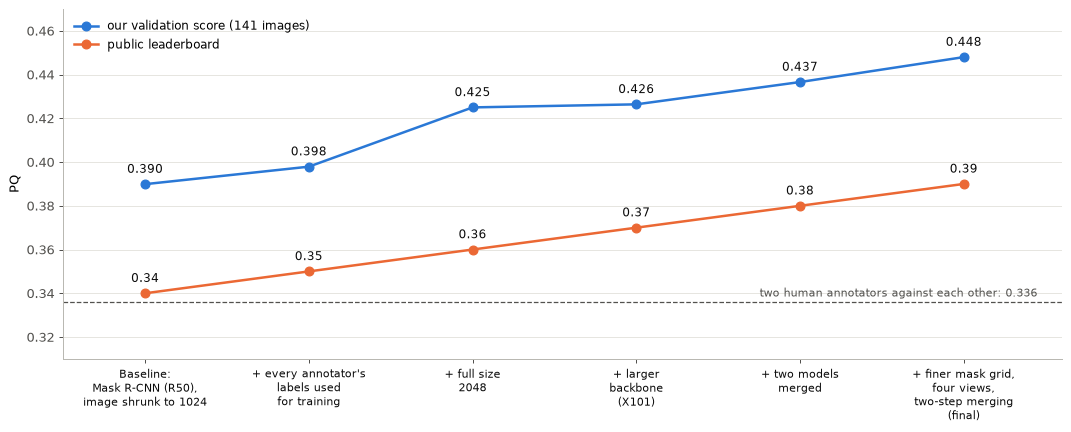

In [21]:
log = pd.read_csv(ROOT / "experiments" / "log.csv").set_index("exp_id")
journey = [
    ("exp004", "Baseline:\nMask R-CNN (R50),\nimage shrunk to 1024"),
    ("exp006", "+ every annotator's\nlabels used\nfor training"),
    ("exp007", "+ full size\n2048"),
    ("exp008", "+ larger\nbackbone\n(X101)"),
    ("exp010", "+ two models\nmerged"),
    ("exp101", "+ finer mask grid,\nfour views,\ntwo-step merging\n(final)"),
]
val = [float(log.loc[e, "val_pq"]) for e, _ in journey]
lb = [float(log.loc[e, "lb_score"]) for e, _ in journey]
x = np.arange(len(journey))

fig, ax = plt.subplots(figsize=(12, 4.9))
ax.plot(x, val, color=BLUE, lw=2, marker="o", ms=7, label="our validation score (141 images)")
ax.plot(x, lb, color=ORANGE, lw=2, marker="o", ms=7, label="public leaderboard")
for xi, v, l in zip(x, val, lb):
    ax.annotate(f"{v:.3f}", (xi, v), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9.5, color=INK)
    ax.annotate(f"{l:.2f}", (xi, l), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9.5, color=INK)
ax.axhline(0.336, color=MUTED, lw=1, ls="--")
ax.text(len(journey) - 0.55, 0.3385, "two human annotators against each other: 0.336", ha="right", fontsize=9, color=MUTED)
ax.set_xticks(x); ax.set_xticklabels([t for _, t in journey], fontsize=9, color=INK)
ax.set_ylim(0.31, 0.47); ax.set_xlim(-0.5, len(journey) - 0.4); ax.set_ylabel("PQ")
ax.grid(axis="y", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=9.5, loc="upper left")
plt.tight_layout(); plt.show()

Just as important is the list of things we tried that did **not** help. Each one was a real experiment with a number
(`experiments/ablation_table.md`). Being able to say why an idea failed shows we understand the problem.

| Idea | What happened | Why, as far as we can tell |
|---|---|---|
| Brighten contrast (CLAHE) and black out everything outside the Sun | No gain (0.390 vs 0.390) | The model already copes with contrast, and it never predicted filaments outside the Sun anyway. |
| Redraw each mask with SAM 2, a general-purpose segmentation model | Worse (0.408 vs 0.426) | SAM draws tighter outlines than our annotators do. Sharper is not what the labels reward. |
| Mask2Former, a newer transformer model | Worse (0.402) | It joined neighbouring filaments into one mask twice as often. |
| Train three times longer | No gain | The model had already learned what 566 images can teach. |
| Rotate and zoom the training images | No gain | Flips already cover most of it. |
| Copy filaments from one image and paste them into another | Slightly worse | More false alarms: pasted filaments do not look fully natural. |
| Label 2,098 extra GONG images with our own model, then train on them | No gain | We kept only very sure labels, so faint filaments stayed unlabelled and the model became more cautious. |
| A third model in the ensemble | Slightly worse (0.4455 vs 0.4480) | It was too similar to the larger model and repeated its mistakes. |
| Train a small extra model to re-score the masks | Worse (0.4423) | 141 validation images with noisy labels are too few to learn a better score from. |
| Re-train the two final models on all 707 images | Same leaderboard score (0.39) | 25% more data changed the test predictions very little: 95% of the masks are the same. |

> **Say it like this:** "The gains came from full resolution, combining two models and four views. We also tested ten
> other ideas properly and dropped them because they did not improve the validation score."

## 12. How we know which gains are real

Half-way through, two changes looked better on validation (+0.002 and +0.004) but scored **lower** on the
leaderboard. We had been chasing noise.

So we measured the noise. The method is called a **paired bootstrap**: draw 141 validation images at random with
repeats, score two pipelines on the same draw, and repeat 2,000 times. That shows how much the difference between two
pipelines moves just because of which images happen to be in the set.

The answer: a gain has to be about **0.010 PQ or more** before we can trust it. We also trained the same model twice
with a different random seed, and the two runs differed by only 0.001, so the noise comes from the small validation
set, not from training.

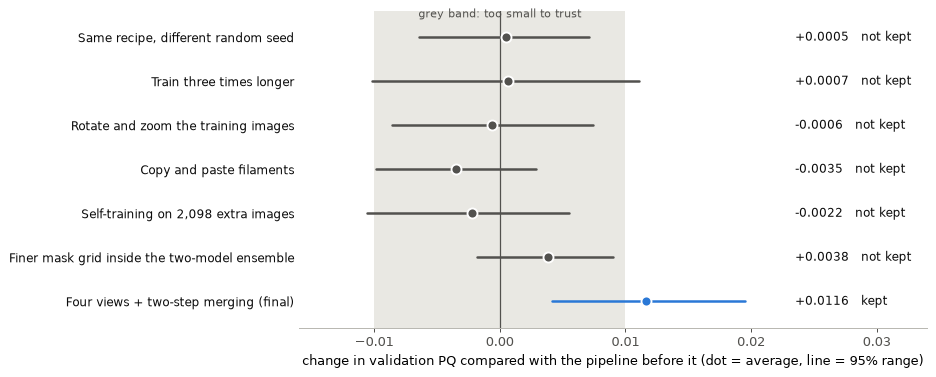

In [22]:
pairs = json.loads((R / "phase6" / "Syaz" / "bootstrap_s5.json").read_text())["pairs"] \
      + json.loads((M / "bootstrap_m2.json").read_text())["pairs"]
def compare(a, b):
    return next(p["val"] for p in pairs if p["A"] == a and p["B"] == b)

trials = [
    ("exp006", "exp201",   "Same recipe, different random seed"),
    ("exp006", "exp202",   "Train three times longer"),
    ("exp006", "exp203",   "Rotate and zoom the training images"),
    ("exp006", "exp204",   "Copy and paste filaments"),
    ("exp006", "exp205",   "Self-training on 2,098 extra images"),
    ("exp010", "exp013",   "Finer mask grid inside the two-model ensemble"),
    ("exp010", "tta2_t06", "Four views + two-step merging (final)"),
]
fig, ax = plt.subplots(figsize=(10.5, 4.3))
ax.axvspan(-0.010, 0.010, color="#e9e8e3", lw=0)
ax.axvline(0, color=MUTED, lw=1)
for y, (a, b, label) in enumerate(reversed(trials)):
    c = compare(a, b)
    real = c["mean_delta"] >= 0.010
    colour = BLUE if real else MUTED
    ax.plot(c["ci95"], [y, y], color=colour, lw=2, solid_capstyle="round")
    ax.plot(c["mean_delta"], y, "o", color=colour, ms=8, mec="white", mew=1.5)
    ax.text(0.0235, y, f"{c['mean_delta']:+.4f}" + ("   kept" if real else "   not kept"), va="center", fontsize=9.5, color=INK)
ax.set_yticks(range(len(trials))); ax.set_yticklabels([t for _, _, t in reversed(trials)], fontsize=9.5, color=INK)
ax.set_xlim(-0.016, 0.034); ax.set_ylim(-0.6, len(trials) - 0.4)
ax.set_xlabel("change in validation PQ compared with the pipeline before it (dot = average, line = 95% range)")
ax.text(0, len(trials) - 0.55, "grey band: too small to trust", ha="center", fontsize=9, color=MUTED)
ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
plt.tight_layout(); plt.show()

Only the last row clears the grey band, and it is the only one of these changes that also moved the leaderboard
(0.38 to 0.39). Every other row sits inside the band. Without this check we might have built our final pipeline out
of several "improvements" that were only luck.

> **Say it like this:** "With 141 validation images, differences below about 0.01 PQ are noise. We measured that with
> a bootstrap and only kept changes that cleared it."

## 13. Where we still lose points

We sorted every error of the final pipeline on the validation images into boxes, and computed how much PQ we would
gain if that box were fixed completely. This tells us what limits the result today.

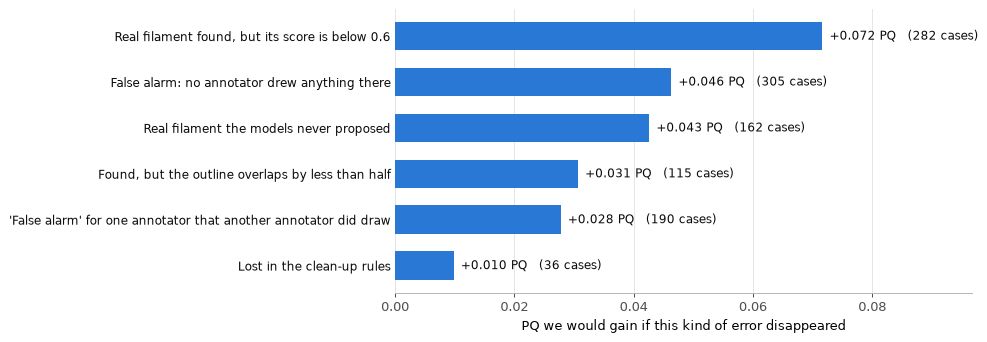

In [23]:
budget = json.loads((M / "error_budget_exp101.json").read_text())
now = budget["all"]["PQ"]
boxes = [
    ("fn_low_score", "Real filament found, but its score is below 0.6"),
    ("fp_nobody",    "False alarm: no annotator drew anything there"),
    ("fn_never",     "Real filament the models never proposed"),
    ("fn_near_miss", "Found, but the outline overlaps by less than half"),
    ("fp_other_ann", "'False alarm' for one annotator that another annotator did draw"),
    ("fn_postproc",  "Lost in the clean-up rules"),
]
gain = [budget["all"]["boxes"][k]["PQ_if_fixed"] - now for k, _ in boxes]
count = [budget["all"]["boxes"][k]["n"] for k, _ in boxes]

fig, ax = plt.subplots(figsize=(11, 3.9))
y = np.arange(len(boxes))[::-1]
ax.barh(y, gain, height=0.62, color=BLUE)
for yi, g, n in zip(y, gain, count):
    ax.text(g + 0.0012, yi, f"+{g:.3f} PQ   ({n} cases)", va="center", fontsize=9.5, color=INK)
ax.set_yticks(y); ax.set_yticklabels([t for _, t in boxes], fontsize=9.5, color=INK)
ax.set_xlim(0, max(gain) * 1.35); ax.set_xlabel("PQ we would gain if this kind of error disappeared")
ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

- **The biggest loss is confidence, not vision.** 282 real filaments were found and drawn well enough, but with a
  score under 0.6, so the cut-off removed them. Lowering the cut-off does not help, because the false alarms sit at
  the same scores (chapter 5). This is the open problem of our pipeline.
- **190 of our "false alarms" were drawn by another annotator of the same image.** That is label noise again. No model
  can avoid it.
- **Small filaments are almost all missed.** There are very few of them (12 in validation), so they cost little.

The score also differs between telescopes, which shows how image quality affects the result:

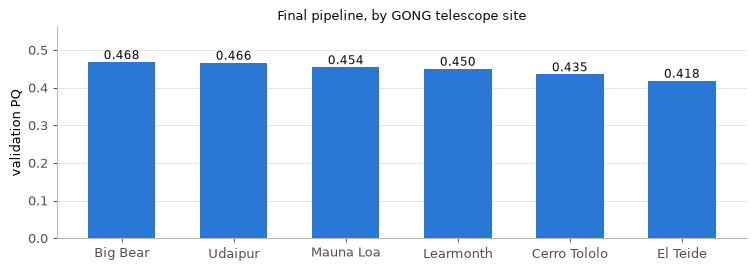

By filament size: small 0.000,  medium 0.430,  large 0.493


In [24]:
sites = {"B": "Big Bear", "C": "Cerro Tololo", "L": "Learmonth", "M": "Mauna Loa", "T": "El Teide", "U": "Udaipur"}
by_site = sorted(((sites[k], v["PQ"]) for k, v in budget["by_station"].items()), key=lambda t: -t[1])
fig, ax = plt.subplots(figsize=(8.5, 3.1))
bars = ax.bar([s for s, _ in by_site], [v for _, v in by_site], width=0.6, color=BLUE)
for b, (_, v) in zip(bars, by_site):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.008, f"{v:.3f}", ha="center", fontsize=9.5, color=INK)
ax.set_ylim(0, 0.56); ax.set_ylabel("validation PQ")
ax.set_title("Final pipeline, by GONG telescope site", fontsize=10, color=INK)
ax.grid(axis="y", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()
print("By filament size:", ",  ".join(f"{k} {v['PQ']:.3f}" for k, v in budget["by_size"].items()))

> **Say it like this:** "Our main remaining loss is not missed filaments but real filaments with a confidence just
> under the cut-off. About a third of our false alarms are filaments that another annotator did draw."

## 14. Speed, and proof that it can be reproduced

On 10 November 2026 we cloned the repository into a fresh Colab session and ran the whole pipeline from the weights
stored in the repository (`notebooks/full_pipeline.ipynb`). These are the numbers that run saved:

In [25]:
run = R / "phase7" / "final_run"
test_run, val_run = (json.loads((run / f"report_{s}.json").read_text()) for s in ("test", "val"))
print(f"Graphics card: {test_run['gpu']}")
print(f"Validation: PQ {val_run['PQ']:.4f}  (hits {val_run['TP']}, false alarms {val_run['FP']}, misses {val_run['FN']})"
      f"  -> same as chapter 10: {abs(val_run['PQ'] - score['PQ']) < 5e-4}")
print(f"Test: {test_run['n_masks']} masks for {test_run['images']} images, file accepted by our validator: {test_run['valid_csv']}")
print(f"Time per image: {test_run['median_s']:.1f} s typical, {test_run['p95_s']:.1f} s for the slowest 5%"
      f"  ({test_run['total_s'] / 60:.0f} minutes for all test images)")
print(f"Peak graphics memory: {test_run['peak_gpu_gb']:.1f} GB")

Graphics card: NVIDIA L4
Validation: PQ 0.4480  (hits 1083, false alarms 495, misses 595)  -> same as chapter 10: True
Test: 1255 masks for 180 images, file accepted by our validator: True
Time per image: 6.0 s typical, 8.2 s for the slowest 5%  (18 minutes for all test images)
Peak graphics memory: 2.9 GB


The six seconds per image are eight model runs (two models × four views) plus merging and clean-up. Training needed
a large card, but prediction fits on a small one.

The submitted file had 1,256 masks. The fresh run found 1,255 of them again; one mask landed just under the 0.6
cut-off because a different graphics card rounds numbers slightly differently.

> **Say it like this:** "Anyone can clone our repository and get the same validation score. Prediction takes about
> six seconds per image and under 3 GB of graphics memory."

## 15. The one-minute version

> We segment solar filaments with **two Mask R-CNN models**, a large one and a small one, both fine-tuned from COCO
> weights on the **full 2048 × 2048 image**, using **every annotator's labels** as training examples.
>
> At test time each model looks at the image **four ways** (normal, mirrored, upside down, both). We merge the four
> views of each model, then merge the two models. A filament keeps a high score only if it is **found repeatedly**.
>
> We then fill small gaps, keep masks with a score of at least 0.6, and remove overlaps.
>
> This scores **PQ 0.448** on 141 held-out images and **0.39** on the public leaderboard. Two human annotators score
> 0.34 against each other. We measured that changes below 0.01 PQ are noise, and kept only changes above that.

## Questions people may ask us

**Why Mask R-CNN and not a newer transformer model?**
We tried one (Mask2Former). It scored lower (0.402 against 0.426) because it merged neighbouring filaments into one
mask twice as often. With only 566 training images, the older and simpler model was more reliable.

**Why two models and not one better model?**
Different models make different mistakes. Requiring agreement removes many false alarms. Together they score 0.448;
the better one alone scores 0.438 at its best cut-off.

**Why union for the four views but intersection for the two models?**
We tested the combinations on validation. Views of one model differ by small shifts, so adding them completes the
outline. The two models differ more, and their shared area matches the annotators best.

**Why is the score cut-off 0.6?**
We tried cut-offs from 0.3 to 0.7 on validation. The score is highest and flat around 0.6 to 0.65.

**Your model scores 0.448 but humans only 0.336. Is the model better than humans?**
No. The 0.336 compares one person with another, and both are "noisy". The model learned from all annotators, so it
draws an average version that is fairly close to each of them. It is more *consistent* than a single person, not
more *correct*.

**Why is the leaderboard (0.39) lower than your validation (0.448)?**
The gap has been steady at 0.05 to 0.06 since our first upload. The public leaderboard uses only about half the test
images and shows two decimals, and the host has said the test scoring has small differences that are not disclosed.
We chose our pipeline on validation only, never on the leaderboard.

**Did you use any data besides the competition data?**
Not in the final model. We downloaded 2,098 extra unlabelled GONG images (allowed by the host, and never from a day
near a test image) and tried self-training. It did not help, so it is not used. We never used outside labels.

**Does the model use the date or the telescope from the file name?**
No. At prediction time it uses only the pixels of the test image.

**What did not work?**
See the table in chapter 11: contrast enhancement, SAM 2, Mask2Former, longer training, rotations, copy-paste,
self-training, a third model, learned re-scoring.

**What would you do with more time?**
Fix the confidence problem from chapter 13: 282 real filaments are found but scored under the cut-off. Options are
more labelled data, or lower-threshold self-training so that faint filaments also get labels.

**How long does it take, and what hardware does it need?**
Training: a few hours per model on an A100 (the large model needs 20 GB). Prediction: 6 seconds per image and under
3 GB of graphics memory.

**How did you make sure you were not fooling yourselves?**
A fixed validation split by time (blocks of 27 days, so the same day is never in both training and validation), our
own copy of the official score checked against the organisers' number, and the noise check from chapter 12.

**Where is the code for each step?**

| Step | File |
|---|---|
| Whole final pipeline | `src/final_pipeline.py` |
| Prediction of one model, with flips | `src/inference.py`, `src/utils/flip.py` |
| Merging views and models | `src/ensemble.py` |
| Clean-up rules | `src/postprocess.py`, `src/utils/rle.py` |
| Official score | `src/evaluate.py` |
| Training | `src/train.py`, `src/dataset.py`, `src/config.py`, `run_pipeline.py` |
| Noise check, error boxes | `src/bootstrap.py`, `src/error_budget.py` |
| Every experiment and its number | `experiments/ablation_table.md`, `experiments/log.csv` |